# Visual Pipeline Example

Loading real images from disk and applying a DALI TorchVision pipeline to visualise the transformations side-by-side.

## Setup

Import the DALI TorchVision API (object-oriented as `dtv`, functional as `dtv_fn`) alongside the standard TorchVision counterparts for comparison.

In [1]:
import torch
import torchvision.transforms.v2 as tv
import torchvision.transforms.v2.functional as tv_fn
from PIL import Image
import numpy as np

# DALI TorchVision API — object-oriented
import nvidia.dali.experimental.torchvision as dtv

# DALI TorchVision API — functional
import nvidia.dali.experimental.torchvision.v2.functional as dtv_fn

In [2]:
import os
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

IMAGE_DIR = "../examples/data/images"


def collect_images(image_dir: str, n: int = 8):
    """Return up to *n* PIL images found recursively under *image_dir*."""
    paths = []
    for root, _, files in os.walk(image_dir):
        for fname in sorted(files):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(root, fname))
    return [Image.open(p).convert("RGB") for p in paths[:n]]


def show_pil_images(images, title: str = "", columns: int = 4):
    """Display a list of PIL images in a grid."""
    n = len(images)
    rows = (n + columns - 1) // columns
    fig = plt.figure(figsize=(16, (16 // columns) * rows))
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    gs = gridspec.GridSpec(rows, columns)
    for j in range(rows * columns):
        ax = plt.subplot(gs[j])
        ax.axis("off")
        if j < n:
            ax.imshow(images[j])
    plt.tight_layout()
    plt.show()


original_images = collect_images(IMAGE_DIR, n=8)
print(f"Loaded {len(original_images)} images")
print("Sizes:", [img.size for img in original_images])

Loaded 8 images
Sizes: [(640, 480), (640, 480), (640, 597), (640, 425), (640, 427), (640, 427), (640, 427), (640, 446)]


/home/mdabek/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Original images

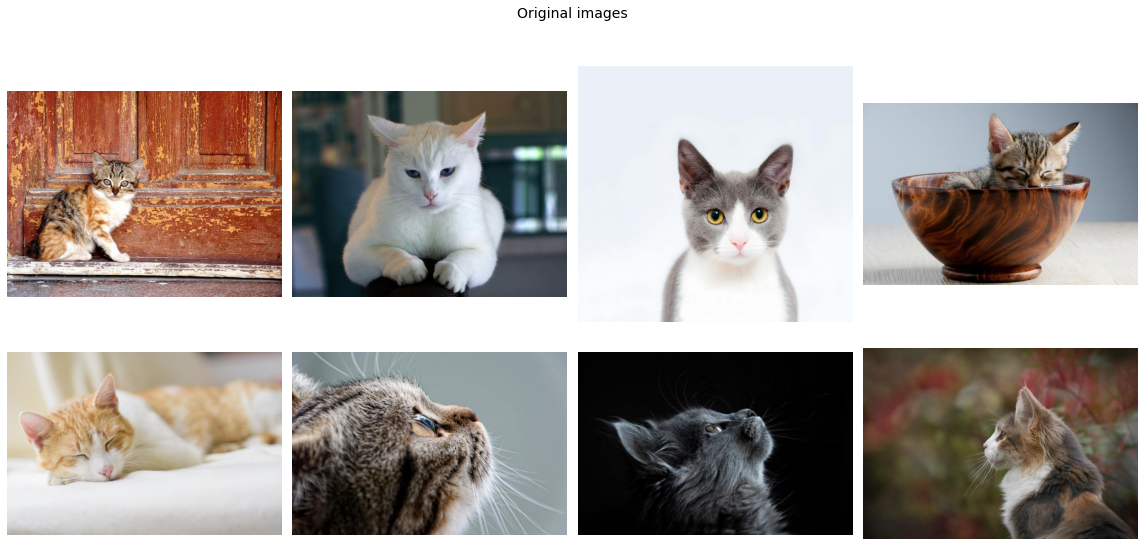

In [3]:
show_pil_images(original_images, title="Original images")

### Augmentation pipeline

Apply a sequence of operators that resize, randomly flip, convert to grayscale, and add padding — the same operators you would use with `torchvision.transforms.v2.Compose`.

In [4]:
augment = dtv.Compose(
    [
        dtv.Resize(size=(128, 128)),
        dtv.RandomHorizontalFlip(p=0.5),
        dtv.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4),
        dtv.Pad(padding=8, padding_mode="reflect"),
    ]
)

augmented_images = [augment(img) for img in original_images]
print(f"Augmented {len(augmented_images)} images")
print("Output sizes:", [img.size for img in augmented_images])

Augmented 8 images
Output sizes: [(144, 144), (144, 144), (144, 144), (144, 144), (144, 144), (144, 144), (144, 144), (144, 144)]


### Augmented images

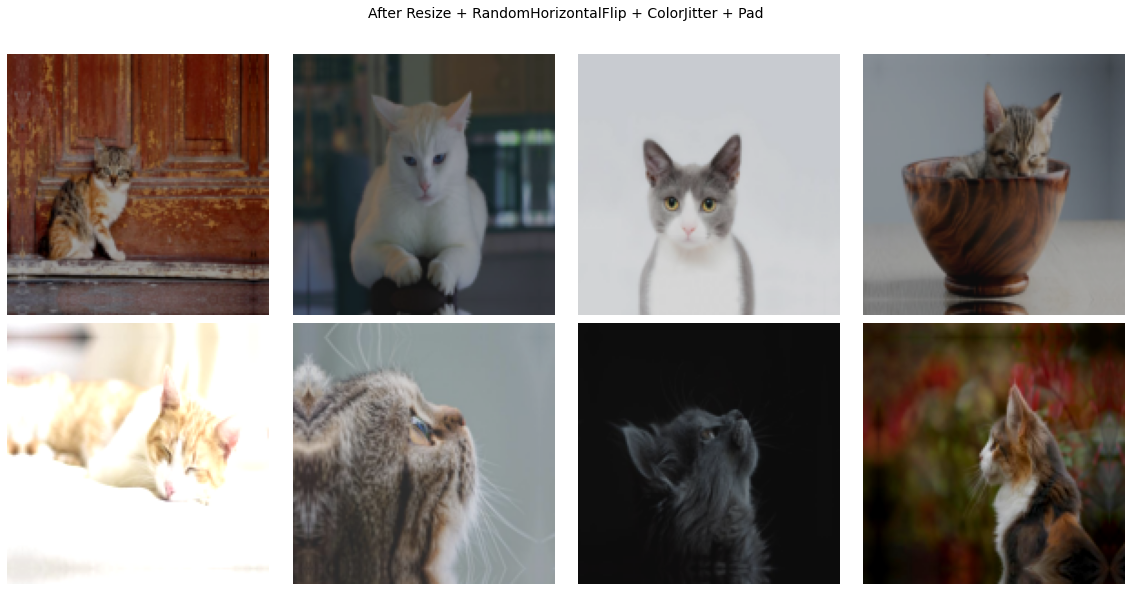

In [5]:
show_pil_images(
    augmented_images,
    title="After Resize + RandomHorizontalFlip + ColorJitter + Pad",
)

## Complete pipeline example

A pre-processing pipeline using the DALI API, following the standard ResNet pre-processing steps — 
structurally identical to the TorchVision version but executed by DALI.

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# --- DALI pipeline ---
dali_preprocess = dtv.Compose(
    [
        dtv.Resize(size=256),
        dtv.CenterCrop(size=(224, 224)),
        dtv.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

# --- Equivalent TorchVision pipeline ---
tv_preprocess = tv.Compose(
    [
        tv.Resize(size=256),
        tv.CenterCrop(size=(224, 224)),
        tv.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

# Use a larger synthetic image to make the resize step meaningful.
# Scale to [0, 1] — ImageNet mean/std constants assume this range.
large_arr = np.random.randint(0, 256, (3, 480, 640), dtype=np.uint8)
large_tensor = (
    torch.from_numpy(large_arr).float() / 255.0
)  # (3, 480, 640), values in [0, 1]

out_dali = dali_preprocess(large_tensor)
out_tv = tv_preprocess(large_tensor)

print("DALI output shape:", out_dali.shape)
print("TV   output shape:", out_tv.shape)
print("Max absolute diff:", (out_dali - out_tv).abs().max().item())

DALI output shape: torch.Size([3, 224, 224])
TV   output shape: torch.Size([3, 224, 224])
Max absolute diff: 4.0471553802490234e-05
